# Title: Holistic Data Prepare 

* Data Acquisition 

Import dataset 

load csv(customer_credit_risk_dataset)

In [279]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [280]:
orignal_csv=pd.read_csv(r"C:\Users\Lenovo\Desktop\DPP final project\customer_credit_risk_dataset.csv")
df_org=orignal_csv.copy()

In [281]:
print(df_org.head(5))
print( df_org.info())
print(df_org.describe())



  customer_id   age  gender region education_level employment_type  \
0  CUST_00001  59.0    Male   West        Graduate        Salaried   
1  CUST_00002  49.0    Male  North        Graduate        Salaried   
2  CUST_00003  35.0    Male  North        Graduate             NaN   
3  CUST_00004  63.0    Male  South        Graduate   Self-Employed   
4  CUST_00005  28.0  Female  South       Secondary   Self-Employed   

   annual_income  loan_amount loan_purpose  credit_score  repayment_history  \
0     1337212.09  24260691.25          Car         675.9                  0   
1      352776.58    227953.44         Home         611.4                  0   
2      420116.16    115270.31     Business         640.4                  2   
3     1740171.03    552253.88         Home         577.3                  2   
4      750558.30    569713.47        Other         589.2                  0   

   transaction_count  spending_ratio   join_date  default_flag  
0                 43            9.54  2

load JSON(behavioral_attributes_dataset)

In [282]:
orignal_json=pd.read_json(r"C:\Users\Lenovo\Desktop\DPP final project\behavioral_attributes_dataset.json")
org2=orignal_json.copy()

In [283]:
print(org2.head(5))
print( org2.info())
print(org2.describe())


    join_date  transaction_count  spending_ratio  missed_payments
0  2024-02-01                 30           0.608                0
1  2024-12-30                 31           0.359                1
2  2023-05-11                 21           0.162                0
3  2024-07-18                 34           0.187                2
4  2024-02-05                 34           0.550                0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   join_date          500 non-null    object 
 1   transaction_count  500 non-null    int64  
 2   spending_ratio     500 non-null    float64
 3   missed_payments    500 non-null    int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 15.8+ KB
None
       transaction_count  spending_ratio  missed_payments
count           500.0000      500.000000       500.000000
mean             28.1260    

In [284]:
org2["join_date"]=pd.to_datetime(org2["join_date"])

load Sqlfile(financial_details.sql)


In [285]:
import sqlite3

conn = sqlite3.connect(":memory:")
with open(r"C:\Users\Lenovo\Desktop\DPP final project\financial_details.sql") as sql_file:
    sql_script = sql_file.read()
conn.executescript(sql_script)

# Query table from SQLite
orignal_sql = pd.read_sql_query("SELECT * FROM financial_details", conn)
orignal_sql.head(5)
org3=orignal_sql.copy()

# Data Understanding & Cleaning

* Explore the dataset using Pandas

In [286]:
print("demographics_dataset")
print("demographics_dataset",df_org.info())
print("\n")
print(df_org.describe())
print("*"* 120)
print("behavioral_attributes_dataset")
print("behavioral_attributes_dataset",org2.info())
print("\n")
print(org2.describe())
print("*"* 120)
print("financial_details")
print("financial_details",org3.info())
print("\n")
print(org3.describe())
print("*"* 120)


demographics_dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1000 non-null   object 
 1   age                920 non-null    float64
 2   gender             950 non-null    object 
 3   region             1000 non-null   object 
 4   education_level    1000 non-null   object 
 5   employment_type    940 non-null    object 
 6   annual_income      930 non-null    float64
 7   loan_amount        1000 non-null   float64
 8   loan_purpose       1000 non-null   object 
 9   credit_score       940 non-null    float64
 10  repayment_history  1000 non-null   int64  
 11  transaction_count  1000 non-null   int64  
 12  spending_ratio     1000 non-null   float64
 13  join_date          1000 non-null   object 
 14  default_flag       1000 non-null   int64  
dtypes: float64(5), int64(3), object(7)
memory usage: 117

* Perform Pandas Profiling to generate a data quality

In [287]:
from ydata_profiling import ProfileReport
profile=ProfileReport(df_org)
profile.to_file(output_file="customer_credit_risk_dataset_Report.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 45.60it/s]


* Handle missing data with:

In [288]:
df_org.isna().sum()

customer_id           0
age                  80
gender               50
region                0
education_level       0
employment_type      60
annual_income        70
loan_amount           0
loan_purpose          0
credit_score         60
repayment_history     0
transaction_count     0
spending_ratio        0
join_date             0
default_flag          0
dtype: int64

Simple Imputer(Numeric)

In [289]:
from sklearn.impute import SimpleImputer
print('Befor the imputation')
print(df_org["age"].isnull().sum())

sm=SimpleImputer(strategy="median")
df_org[["age"]]=sm.fit_transform(df_org[["age"]])
data=pd.DataFrame(df_org)

print('After the imputation')
print(df_org["age"].isnull().sum())

Befor the imputation
80
After the imputation
0


Simple Imputer(categorical)

In [290]:
print("befor imputation",df_org["employment_type"].isnull().sum())

si=SimpleImputer(strategy="most_frequent")
df_org[["employment_type"]]=si.fit_transform(df_org[["employment_type"]])
print("After imputation",df_org.employment_type.isnull().sum())

befor imputation 60
After imputation 0


Most Frequent Category Imputation

In [291]:
print("befor imputation",df_org.gender.isnull().sum())

si=SimpleImputer(strategy="most_frequent")
df_org[["gender"]]=si.fit_transform(df_org[["gender"]])
print("After imputation",df_org.gender.isnull().sum())

befor imputation 50
After imputation 0


Missing Indicator + Random Sample Imputation

In [292]:
print("befor imputation",df_org.annual_income .isnull().sum())
org=df_org.copy()
org['miss_annual_income ']= org.annual_income .isnull().astype(int)

r_s=org['annual_income'].dropna().sample(org['annual_income'].isnull().sum(),random_state=42)
r_s.index= org[df_org['annual_income'].isnull()].index
org.loc[org['annual_income'].isnull(),"annual_income"]=r_s
org['annual_income'].isnull().sum()
print("After imputation",org.annual_income.isnull().sum())
 
 

befor imputation 70
After imputation 0


KNN Imputer: multivariate

In [293]:
from sklearn.impute import KNNImputer
df_m=df_org.copy()
print("Befor the imputation",df_m.isnull().sum())
df_org.columns.tolist()
cols=['annual_income','loan_amount','credit_score']
imp=KNNImputer(n_neighbors=5,weights='uniform')      
df_org[cols]= imp.fit_transform(df_org[cols])
print('After the imputation',df_org.isnull().sum())

Befor the imputation customer_id           0
age                   0
gender                0
region                0
education_level       0
employment_type       0
annual_income        70
loan_amount           0
loan_purpose          0
credit_score         60
repayment_history     0
transaction_count     0
spending_ratio        0
join_date             0
default_flag          0
dtype: int64
After the imputation customer_id          0
age                  0
gender               0
region               0
education_level      0
employment_type      0
annual_income        0
loan_amount          0
loan_purpose         0
credit_score         0
repayment_history    0
transaction_count    0
spending_ratio       0
join_date            0
default_flag         0
dtype: int64


MICE Algorithm

In [294]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
org2=df_m.copy()
print("Befor the imputation",org2.isnull().sum())

mice_imputer = IterativeImputer(max_iter=10,random_state=42,)
df_mice = org2.copy()
df_mice[cols] = mice_imputer.fit_transform(org2[cols])
print('After the imputation',df_mice.isnull().sum())

Befor the imputation customer_id           0
age                   0
gender                0
region                0
education_level       0
employment_type       0
annual_income        70
loan_amount           0
loan_purpose          0
credit_score         60
repayment_history     0
transaction_count     0
spending_ratio        0
join_date             0
default_flag          0
dtype: int64
After the imputation customer_id          0
age                  0
gender               0
region               0
education_level      0
employment_type      0
annual_income        0
loan_amount          0
loan_purpose         0
credit_score         0
repayment_history    0
transaction_count    0
spending_ratio       0
join_date            0
default_flag         0
dtype: int64


Complete Case Analysis: dropping rows or columns

# Outlier Handling

* Detect and treat outliers

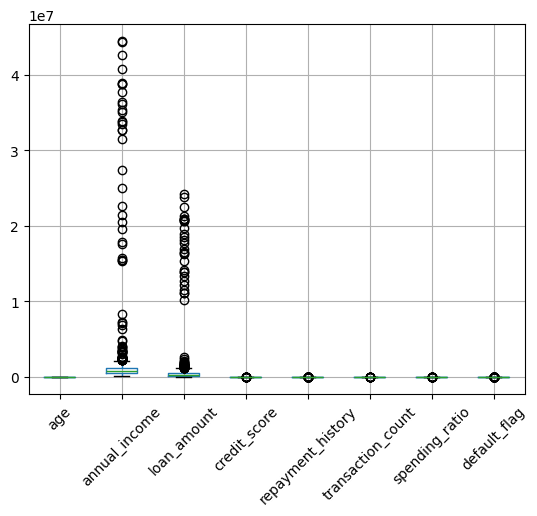

In [295]:
%matplotlib inline
df_org.boxplot()
plt.xticks(rotation=45)
plt.show()

Z-score Method

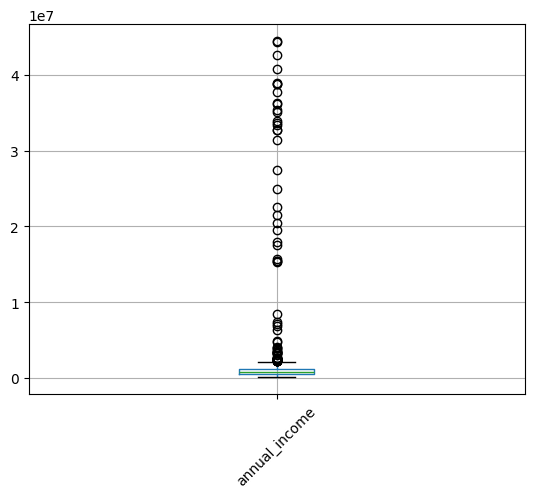

In [296]:
df_z=df_org.copy()
df_z.boxplot(["annual_income"])
plt.xticks(rotation=45)
plt.show()

In [297]:
df_z=df_org.copy()
# befor
df_z.shape

(1000, 15)

In [298]:

m=df_z["annual_income"].mean()
s=df_z["annual_income"].std()
df_z['annual_income_z']=(df_z["annual_income"]-m)/s
df_z=df_z[df_z['annual_income_z'].abs()<3]


In [299]:
# after
df_z.shape

(975, 16)

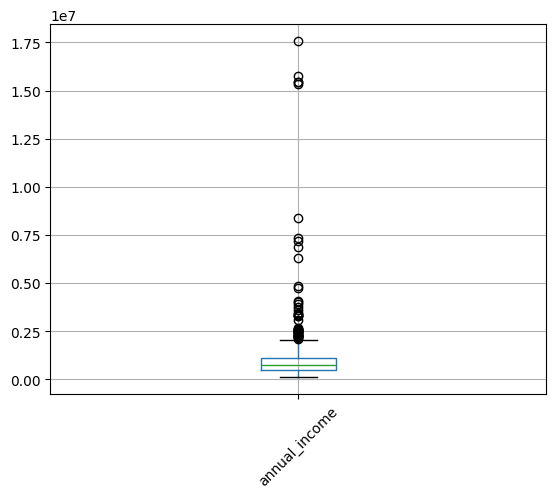

In [300]:
df_z.boxplot(["annual_income"])
plt.xticks(rotation=45)
plt.show()

IQR Method

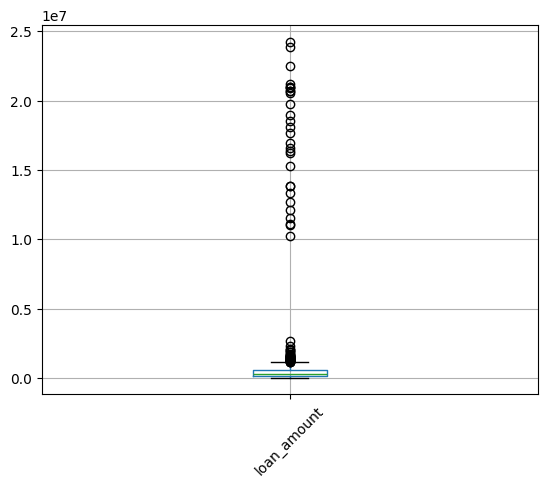

(975, 16)

In [301]:
df_z.boxplot(["loan_amount"])
plt.xticks(rotation=45)
plt.show()
df_z.shape

In [302]:
q1=df_z['loan_amount'].quantile(0.25)
q3=df_z['loan_amount'].quantile(0.75)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
df_z[(df_z['loan_amount'] > lower) & (df_z['loan_amount'] < upper)]
df_z=df_z[(df_z['loan_amount'] >= lower) & (df_z['loan_amount'] <= upper)]

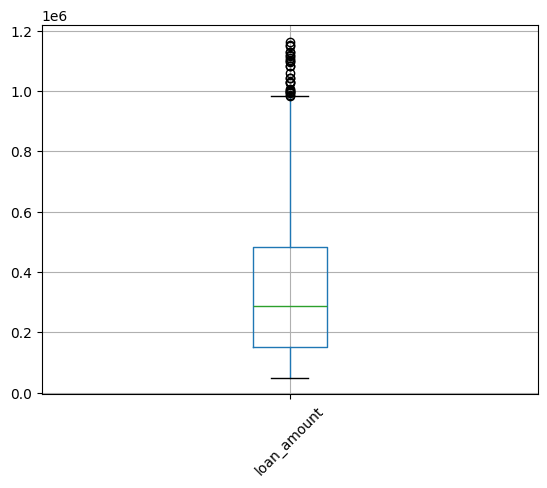

(909, 16)

In [303]:
df_z.boxplot(["loan_amount"])
plt.xticks(rotation=45)
plt.show()
df_z.shape

Percentile Method

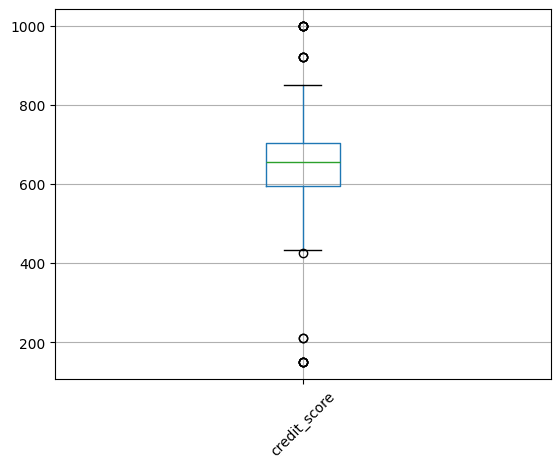

In [304]:
df_z.boxplot(["credit_score"])
plt.xticks(rotation=45)
plt.show()

In [305]:
upp=df_z['credit_score'].quantile(0.95)
lor=df_z['credit_score'].quantile(0.05)
df_z[(df_z['credit_score']<upp) & (df_z['credit_score']>lor)]
df_z=df_z[(df_z['credit_score']<upp) & (df_z['credit_score']>lor)]

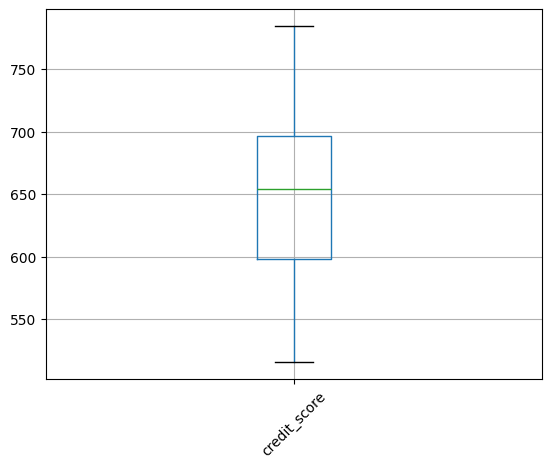

In [306]:
df_z.boxplot(["credit_score"])
plt.xticks(rotation=45)
plt.show()

Winsorization Technique


In [307]:
u=df_z['repayment_history'].quantile(0.95)
l=df_z['repayment_history'].quantile(0.05)
df_z['repayment_history_clip']=df_z['repayment_history'].clip(lower=l, upper=u)
df_z[['repayment_history_clip', 'repayment_history']].describe()


,repayment_history_clip,repayment_history
count,817.000000,817.000000
mean,0.809058,1.268054
std,0.894025,3.461323
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,3.000000,29.000000


# Feature Engineering

* Handle variable types

In [308]:
df_z.dtypes

customer_id                object
age                       float64
gender                     object
region                     object
education_level            object
employment_type            object
annual_income             float64
loan_amount               float64
loan_purpose               object
credit_score              float64
repayment_history           int64
transaction_count           int64
spending_ratio            float64
join_date                  object
default_flag                int64
annual_income_z           float64
repayment_history_clip      int64
dtype: object

Date & Time variables → extract Year, Month, Day, Weekday

In [309]:
df_z['join_date']=pd.to_datetime(df_z['join_date'])
df_z['year']=df_z['join_date'].dt.year
df_z['month']=df_z['join_date'].dt.month
df_z['day']=df_z['join_date'].dt.day
df_z['weekday']=df_z['join_date'].dt.weekday
df_z    

,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,...,transaction_count,spending_ratio,join_date,default_flag,annual_income_z,repayment_history_clip,year,month,day,weekday
1,CUST_00002,49.0,Male,North,Graduate,Salaried,352776.58,227953.44,Home,611.4,...,35,20.40,2022-11-15,0,-0.274801,0,2022,11,15,1
2,CUST_00003,35.0,Male,North,Graduate,Salaried,420116.16,115270.31,Business,640.4,...,24,116.94,2016-04-03,0,-0.262051,2,2016,4,3,6
3,CUST_00004,63.0,Male,South,Graduate,Self-Employed,1740171.03,552253.88,Home,577.3,...,25,13.10,2018-10-17,0,-0.012106,2,2018,10,17,2
4,CUST_00005,28.0,Female,South,Secondary,Self-Employed,750558.30,569713.47,Other,589.2,...,56,43.72,2021-05-13,0,-0.199484,0,2021,5,13,3
5,CUST_00006,41.0,Female,West,Graduate,Salaried,657254.66,778143.48,Home,693.5,...,54,32.74,2019-10-07,0,-0.217150,1,2019,10,7,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CUST_00996,25.0,Male,North,Secondary,Salaried,580534.52,83529.84,Business,657.0,...,50,30.39,2021-01-05,0,-0.231677,0,2021,1,5,1
996,CUST_00997,43.0,Male,North,Graduate,Unemployed,561838.07,245153.83,Home,621.5,...,17,13.39,2020-12-26,0,-0.235217,1,2020,12,26,5
997,CUST_00998,30.0,Male,North,Graduate,Self-Employed,1730970.97,100677.23,Education,592.2,...,57,55.28,2020-12-21,0,-0.013848,1,2020,12,21,0
998,CUST_00999,64.0,Male,North,Graduate,Salaried,283440.41,907350.71,Home,568.5,...,33,71.74,2025-10-30,0,-0.287930,0,2025,10,30,3


# Encoding categorical variables

 Ordinal Encoding: education levels

In [310]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder(categories=[['Primary', 'Secondary', 'Graduate','Post-Graduate']])
df_z[['education_level']] = oe.fit_transform(df_z[['education_level']])

In [311]:
df_z

,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,...,transaction_count,spending_ratio,join_date,default_flag,annual_income_z,repayment_history_clip,year,month,day,weekday
1,CUST_00002,49.0,Male,North,2.0,Salaried,352776.58,227953.44,Home,611.4,...,35,20.40,2022-11-15,0,-0.274801,0,2022,11,15,1
2,CUST_00003,35.0,Male,North,2.0,Salaried,420116.16,115270.31,Business,640.4,...,24,116.94,2016-04-03,0,-0.262051,2,2016,4,3,6
3,CUST_00004,63.0,Male,South,2.0,Self-Employed,1740171.03,552253.88,Home,577.3,...,25,13.10,2018-10-17,0,-0.012106,2,2018,10,17,2
4,CUST_00005,28.0,Female,South,1.0,Self-Employed,750558.30,569713.47,Other,589.2,...,56,43.72,2021-05-13,0,-0.199484,0,2021,5,13,3
5,CUST_00006,41.0,Female,West,2.0,Salaried,657254.66,778143.48,Home,693.5,...,54,32.74,2019-10-07,0,-0.217150,1,2019,10,7,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CUST_00996,25.0,Male,North,1.0,Salaried,580534.52,83529.84,Business,657.0,...,50,30.39,2021-01-05,0,-0.231677,0,2021,1,5,1
996,CUST_00997,43.0,Male,North,2.0,Unemployed,561838.07,245153.83,Home,621.5,...,17,13.39,2020-12-26,0,-0.235217,1,2020,12,26,5
997,CUST_00998,30.0,Male,North,2.0,Self-Employed,1730970.97,100677.23,Education,592.2,...,57,55.28,2020-12-21,0,-0.013848,1,2020,12,21,0
998,CUST_00999,64.0,Male,North,2.0,Salaried,283440.41,907350.71,Home,568.5,...,33,71.74,2025-10-30,0,-0.287930,0,2025,10,30,3


Label Encoding: binary features

In [314]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df_z['gender_lebel'] = encoder.fit_transform(df_z['gender'])
df_z

,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,...,spending_ratio,join_date,default_flag,annual_income_z,repayment_history_clip,year,month,day,weekday,gender_lebel
1,CUST_00002,49.0,Male,North,2.0,Salaried,352776.58,227953.44,Home,611.4,...,20.40,2022-11-15,0,-0.274801,0,2022,11,15,1,1
2,CUST_00003,35.0,Male,North,2.0,Salaried,420116.16,115270.31,Business,640.4,...,116.94,2016-04-03,0,-0.262051,2,2016,4,3,6,1
3,CUST_00004,63.0,Male,South,2.0,Self-Employed,1740171.03,552253.88,Home,577.3,...,13.10,2018-10-17,0,-0.012106,2,2018,10,17,2,1
4,CUST_00005,28.0,Female,South,1.0,Self-Employed,750558.30,569713.47,Other,589.2,...,43.72,2021-05-13,0,-0.199484,0,2021,5,13,3,0
5,CUST_00006,41.0,Female,West,2.0,Salaried,657254.66,778143.48,Home,693.5,...,32.74,2019-10-07,0,-0.217150,1,2019,10,7,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CUST_00996,25.0,Male,North,1.0,Salaried,580534.52,83529.84,Business,657.0,...,30.39,2021-01-05,0,-0.231677,0,2021,1,5,1,1
996,CUST_00997,43.0,Male,North,2.0,Unemployed,561838.07,245153.83,Home,621.5,...,13.39,2020-12-26,0,-0.235217,1,2020,12,26,5,1
997,CUST_00998,30.0,Male,North,2.0,Self-Employed,1730970.97,100677.23,Education,592.2,...,55.28,2020-12-21,0,-0.013848,1,2020,12,21,0,1
998,CUST_00999,64.0,Male,North,2.0,Salaried,283440.41,907350.71,Home,568.5,...,71.74,2025-10-30,0,-0.287930,0,2025,10,30,3,1


One-Hot Encoding: regions, loan purpose

In [315]:
df_z = pd.get_dummies(df_z, columns=['region'], dtype=int, drop_first=True)
df_z.head()

,customer_id,age,gender,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,...,annual_income_z,repayment_history_clip,year,month,day,weekday,gender_lebel,region_North,region_South,region_West
1,CUST_00002,49.0,Male,2.0,Salaried,352776.58,227953.44,Home,611.4,0,...,-0.274801,0,2022,11,15,1,1,1,0,0
2,CUST_00003,35.0,Male,2.0,Salaried,420116.16,115270.31,Business,640.4,2,...,-0.262051,2,2016,4,3,6,1,1,0,0
3,CUST_00004,63.0,Male,2.0,Self-Employed,1740171.03,552253.88,Home,577.3,2,...,-0.012106,2,2018,10,17,2,1,0,1,0
4,CUST_00005,28.0,Female,1.0,Self-Employed,750558.30,569713.47,Other,589.2,0,...,-0.199484,0,2021,5,13,3,0,0,1,0
5,CUST_00006,41.0,Female,2.0,Salaried,657254.66,778143.48,Home,693.5,1,...,-0.217150,1,2019,10,7,0,0,0,0,1


# Encoding numerical features

Binning:

In [316]:
df_z['repayment_category_bin'] = pd.cut(
    df_z['repayment_history'],
    bins=3,                                 
    labels=['Low', 'Medium', 'High']
)
df_z

,customer_id,age,gender,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,...,repayment_history_clip,year,month,day,weekday,gender_lebel,region_North,region_South,region_West,repayment_category_bin
1,CUST_00002,49.0,Male,2.0,Salaried,352776.58,227953.44,Home,611.4,0,...,0,2022,11,15,1,1,1,0,0,Low
2,CUST_00003,35.0,Male,2.0,Salaried,420116.16,115270.31,Business,640.4,2,...,2,2016,4,3,6,1,1,0,0,Low
3,CUST_00004,63.0,Male,2.0,Self-Employed,1740171.03,552253.88,Home,577.3,2,...,2,2018,10,17,2,1,0,1,0,Low
4,CUST_00005,28.0,Female,1.0,Self-Employed,750558.30,569713.47,Other,589.2,0,...,0,2021,5,13,3,0,0,1,0,Low
5,CUST_00006,41.0,Female,2.0,Salaried,657254.66,778143.48,Home,693.5,1,...,1,2019,10,7,0,0,0,0,1,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CUST_00996,25.0,Male,1.0,Salaried,580534.52,83529.84,Business,657.0,0,...,0,2021,1,5,1,1,1,0,0,Low
996,CUST_00997,43.0,Male,2.0,Unemployed,561838.07,245153.83,Home,621.5,1,...,1,2020,12,26,5,1,1,0,0,Low
997,CUST_00998,30.0,Male,2.0,Self-Employed,1730970.97,100677.23,Education,592.2,1,...,1,2020,12,21,0,1,1,0,0,Low
998,CUST_00999,64.0,Male,2.0,Salaried,283440.41,907350.71,Home,568.5,0,...,0,2025,10,30,3,1,1,0,0,Low


Binarization: flag if > threshold

In [317]:
from sklearn.preprocessing import Binarizer

cs = Binarizer(threshold=700)
df_z['credit_score>700'] = cs.fit_transform(df_z[['credit_score']])


Quantile Binning

In [318]:
from sklearn.preprocessing import KBinsDiscretizer
kbd = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
df_z[['transaction_qbin']] = kbd.fit_transform(df_z[['transaction_count']])

K-Means Binning

In [319]:
kmb = KBinsDiscretizer(n_bins=3,encode='ordinal',strategy='kmeans'      )
df_z[['cs_kmb']] = kmb.fit_transform(df_z[['credit_score']])
df_z

,customer_id,age,gender,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,...,day,weekday,gender_lebel,region_North,region_South,region_West,repayment_category_bin,credit_score>700,transaction_qbin,cs_kmb
1,CUST_00002,49.0,Male,2.0,Salaried,352776.58,227953.44,Home,611.4,0,...,15,1,1,1,0,0,Low,0.0,1.0,0.0
2,CUST_00003,35.0,Male,2.0,Salaried,420116.16,115270.31,Business,640.4,2,...,3,6,1,1,0,0,Low,0.0,0.0,1.0
3,CUST_00004,63.0,Male,2.0,Self-Employed,1740171.03,552253.88,Home,577.3,2,...,17,2,1,0,1,0,Low,0.0,0.0,0.0
4,CUST_00005,28.0,Female,1.0,Self-Employed,750558.30,569713.47,Other,589.2,0,...,13,3,0,0,1,0,Low,0.0,3.0,0.0
5,CUST_00006,41.0,Female,2.0,Salaried,657254.66,778143.48,Home,693.5,1,...,7,0,0,0,0,1,Low,0.0,3.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CUST_00996,25.0,Male,1.0,Salaried,580534.52,83529.84,Business,657.0,0,...,5,1,1,1,0,0,Low,0.0,3.0,1.0
996,CUST_00997,43.0,Male,2.0,Unemployed,561838.07,245153.83,Home,621.5,1,...,26,5,1,1,0,0,Low,0.0,0.0,1.0
997,CUST_00998,30.0,Male,2.0,Self-Employed,1730970.97,100677.23,Education,592.2,1,...,21,0,1,1,0,0,Low,0.0,3.0,0.0
998,CUST_00999,64.0,Male,2.0,Salaried,283440.41,907350.71,Home,568.5,0,...,30,3,1,1,0,0,Low,0.0,1.0,0.0


# Feature Scaling

* Apply multiple scaling methods

Standardization: Z-score scaling

In [320]:
from sklearn.preprocessing import StandardScaler
sscale = StandardScaler()
df_z[['income_std','loan_std']] = sscale.fit_transform(df_z[['annual_income','loan_amount']])

Normalization

In [321]:
from sklearn.preprocessing import Normalizer
nor = Normalizer()
df_z[['income_nor','loan_nor']] = nor.fit_transform(df_z[['annual_income','loan_amount']])

Min-Max Scaling

In [322]:
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler()
df_z[['income_mms','loan_mms']] = mms.fit_transform(df_z[['annual_income','loan_amount']])

MaxAbs Scaling

In [323]:
from sklearn.preprocessing import MaxAbsScaler
mabs = MaxAbsScaler()
df_z[['income_mabs','loan_mabs']] = mabs.fit_transform(df_z[['annual_income','loan_amount']])

Robust Scaling

In [ ]:
from sklearn.preprocessing import RobustScaler
rs = RobustScaler()
df_z[['income_robust','loan_robust']] = rs.fit_transform(df_z[['annual_income','loan_amount']])

In [324]:
df_z.describe()

,age,education_level,annual_income,loan_amount,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag,...,transaction_qbin,cs_kmb,income_std,loan_std,income_nor,loan_nor,income_mms,loan_mms,income_mabs,loan_mabs
count,817.000000,817.000000,8.170000e+02,8.170000e+02,817.000000,817.000000,817.000000,817.000000,817,817.000000,...,817.000000,817.000000,8.170000e+02,8.170000e+02,817.000000,817.000000,817.000000,817.000000,817.000000,817.000000
mean,44.055080,1.578947,1.008750e+06,3.466331e+05,650.669351,1.268054,40.130967,39.156242,2020-12-30 17:58:40.685434624,0.066095,...,1.525092,0.940024,6.087881e-17,-9.566671e-17,0.869579,0.392443,0.051155,0.265991,0.057420,0.297767
min,21.000000,0.000000,1.159977e+05,5.039624e+04,515.600000,0.000000,9.000000,2.190000,2016-01-04 00:00:00,0.000000,...,0.000000,0.000000,-6.483655e-01,-1.188362e+00,0.157856,0.010278,0.000000,0.000000,0.006603,0.043292
25%,34.000000,1.000000,4.941904e+05,1.480081e+05,598.400000,0.000000,30.000000,20.520000,2018-08-05 00:00:00,0.000000,...,1.000000,0.000000,-3.737012e-01,-7.967892e-01,0.803678,0.166289,0.021670,0.087646,0.028130,0.127143
50%,44.000000,2.000000,7.700341e+05,2.858230e+05,654.400000,1.000000,39.000000,33.870000,2021-01-26 00:00:00,0.000000,...,2.000000,1.000000,-1.733684e-01,-2.439413e-01,0.936725,0.350065,0.037476,0.211390,0.043832,0.245530
75%,55.000000,2.000000,1.146312e+06,4.777035e+05,696.500000,1.000000,48.000000,52.260000,2023-06-07 00:00:00,0.000000,...,3.000000,2.000000,9.990514e-02,5.257925e-01,0.986077,0.595065,0.059037,0.383679,0.065250,0.410361
max,67.000000,3.000000,1.756799e+07,1.164106e+06,784.500000,29.000000,115.000000,178.590000,2025-12-21 00:00:00,1.000000,...,3.000000,2.000000,1.202623e+01,3.279315e+00,0.999947,0.987462,1.000000,1.000000,1.000000,1.000000
std,12.979175,0.843921,1.377771e+06,2.494344e+05,65.681934,3.461323,14.322313,24.656596,NaN,0.248601,...,1.134214,0.747595,1.000613e+00,1.000613e+00,0.157187,0.255387,0.078946,0.223967,0.078425,0.214271


# Feature Construction & Transformation

* Apply transformations

FunctionTransformer → log transform, reciprocal, square root

In [326]:
from sklearn.preprocessing import FunctionTransformer

log_t = FunctionTransformer(np.log1p)
rec_t = FunctionTransformer(np.reciprocal)
sqrt_t = FunctionTransformer(np.sqrt)

df_z['spending_log'] = log_t.fit_transform(df_z[['spending_ratio']])
df_z['spending_reciprocal'] = rec_t.fit_transform(df_z[['spending_ratio']])
df_z['spending_sqrt'] = sqrt_t.fit_transform(df_z[['spending_ratio']])

PowerTransformer → Box-Cox and Yeo-Johnson.

In [327]:
from sklearn.preprocessing import PowerTransformer

bc = PowerTransformer(method='box-cox')
df_z[['b_c_income','b_c_loan']] = bc.fit_transform(df_z[['annual_income','loan_amount']])

yj = PowerTransformer(method='yeo-johnson')
df_z[['y_j_income','y_j_loan']] = yj.fit_transform(df_z[['annual_income','loan_amount']])

Column Transformer → apply different preprocessing steps to different columns.

In [328]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

c_t = ColumnTransformer([('num', StandardScaler(), ['age','credit_score','transaction_count']),('cat', OneHotEncoder(drop='first', sparse_output=False), ['employment_type'])])
c_t_1 = c_t.fit_transform(df_z)
df_c_t = pd.DataFrame(c_t_1, columns=c_t.get_feature_names_out())
df_c_t.head(5)


,num__age,num__credit_score,num__transaction_count,cat__employment_type_Self-Employed,cat__employment_type_Unemployed
0,0.381222,-0.598238,-0.358469,0.0,0.0
1,-0.698090,-0.156445,-1.126972,0.0,0.0
2,1.460534,-1.117724,-1.057108,1.0,0.0
3,-1.237745,-0.936437,1.108672,1.0,0.0
4,-0.235527,0.652491,0.968945,0.0,0.0


* Construct new features

Debt-to-Income ratio

In [ ]:
df_z['debt_to_income'] = df_z['loan_amount'] / df_z['annual_income']

Average monthly transactions

In [329]:
df_z['avg_monthly_transaction'] = df_z['transaction_count'] / 12

Spending-to-Income ratio

In [330]:
df_z['spending_to_income'] = df_z['spending_ratio'] / 100

# Final dataset

In [333]:
df_z.to_csv('final_dataset.csv',index=False)